In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [9]:
columns=['Variance','Skewness','Curtosis','Entropy','Class(Target)']
df=pd.read_csv("data_banknote_authentication.txt",sep=',',names=columns)
df

,Variance,Skewness,Curtosis,Entropy,Class(Target)
0,3.62160,8.66610,-2.8073,-0.44699,0
1,4.54590,8.16740,-2.4586,-1.46210,0
2,3.86600,-2.63830,1.9242,0.10645,0
3,3.45660,9.52280,-4.0112,-3.59440,0
4,0.32924,-4.45520,4.5718,-0.98880,0
...,...,...,...,...,...
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1


In [11]:
def indication(x):
    if x==0:
      return "Genuine banknote"
    else :
        return "Forged banknote"  
df["Representation"]=df["Class(Target)"].apply(indication)
df

,Variance,Skewness,Curtosis,Entropy,Class(Target),Representation
0,3.62160,8.66610,-2.8073,-0.44699,0,Genuine banknote
1,4.54590,8.16740,-2.4586,-1.46210,0,Genuine banknote
2,3.86600,-2.63830,1.9242,0.10645,0,Genuine banknote
3,3.45660,9.52280,-4.0112,-3.59440,0,Genuine banknote
4,0.32924,-4.45520,4.5718,-0.98880,0,Genuine banknote
...,...,...,...,...,...,...
1367,0.40614,1.34920,-1.4501,-0.55949,1,Forged banknote
1368,-1.38870,-4.87730,6.4774,0.34179,1,Forged banknote
1369,-3.75030,-13.45860,17.5932,-2.77710,1,Forged banknote
1370,-3.56370,-8.38270,12.3930,-1.28230,1,Forged banknote


In [14]:
df.info()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Variance        1372 non-null   float64
 1   Skewness        1372 non-null   float64
 2   Curtosis        1372 non-null   float64
 3   Entropy         1372 non-null   float64
 4   Class(Target)   1372 non-null   int64  
 5   Representation  1372 non-null   str    
dtypes: float64(4), int64(1), str(1)
memory usage: 64.4 KB


,Variance,Skewness,Curtosis,Entropy,Class(Target)
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [21]:
#for checking whether data is imbalanced or not?
df["Class(Target)"].value_counts(normalize=True)

X=df.iloc[:,0:4]
X
Y=df.iloc[:,-2]
Y

0       0
1       0
2       0
3       0
4       0
       ..
1367    1
1368    1
1369    1
1370    1
1371    1
Name: Class(Target), Length: 1372, dtype: int64

In [71]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,random_state=3,test_size=0.2)
X_train

,Variance,Skewness,Curtosis,Entropy
301,2.971900,6.83690,-0.27020,0.712910
1015,-0.907840,-7.90260,6.78070,0.341790
1322,-0.973250,-6.41680,5.60260,1.032300
1228,-1.341400,-1.91620,-0.15538,-0.119840
946,-0.001285,0.13863,-0.19651,0.008175
...,...,...,...,...
789,1.055200,1.18570,-2.64110,0.110330
256,3.093400,-2.91770,2.22320,0.222830
968,-1.955500,0.20692,1.24730,-0.370700
952,-1.284600,3.27150,-1.76710,-3.260800


In [72]:
#feature scalaing
scalar=StandardScaler()
X_train=scalar.fit_transform(X_train)
X_test=scalar.transform(X_test)

In [110]:
knn=KNeighborsClassifier(n_neighbors=5,metric="minkowski",p=2)
knn.fit(X_train,Y_train)
y_pred=knn.predict(X_test)

In [121]:
from sklearn.metrics import accuracy_score,confusion_matrix
print("Accuracy score",accuracy_score(Y_test,y_pred))
print("Confusion Matrix",confusion_matrix(Y_test,y_pred))

Accuracy score 0.9963636363636363
Confusion Matrix [[167   1]
 [  0 107]]


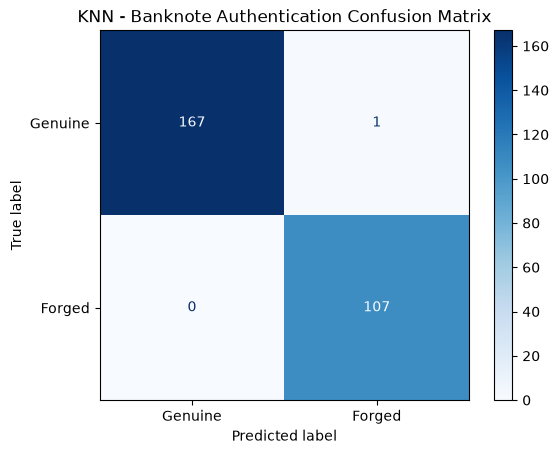

In [98]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("Images", exist_ok=True)

cm = confusion_matrix(Y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Forged"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("KNN - Banknote Authentication Confusion Matrix")
plt.savefig("Images/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Best K: 1
Mean CV accuracy: 0.9990867579908675


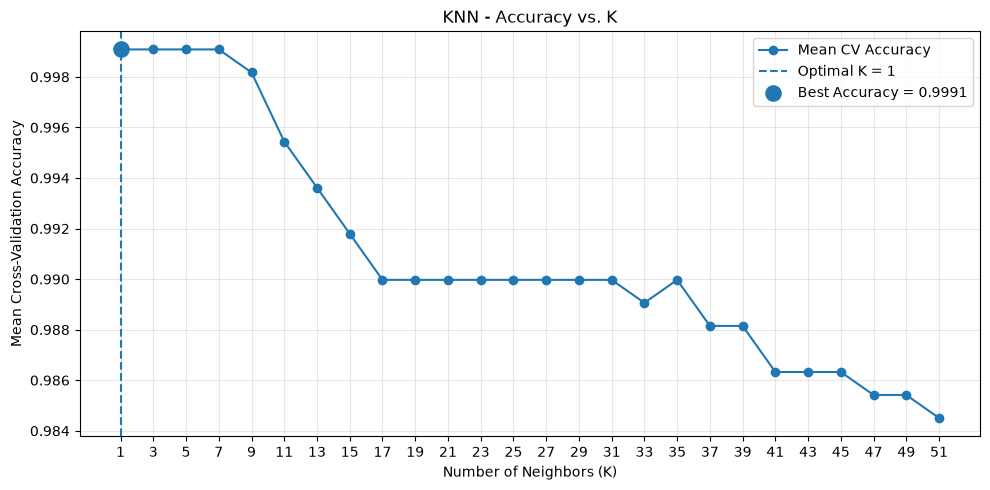

In [107]:
import numpy as np
from sklearn.model_selection import StratifiedKFold

X = np.asarray(X_train)
y = np.asarray(Y_train).ravel()

k_values = range(1, 52, 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_scores = []

for k in k_values:
    fold_scores = []

    for train_idx, val_idx in cv.split(X, y):
        X_fold_train = X[train_idx]
        X_fold_val = X[val_idx]
        y_fold_train = y[train_idx]
        y_fold_val = y[val_idx]

        scaler = StandardScaler()
        X_fold_train_scaled = scaler.fit_transform(X_fold_train)
        X_fold_val_scaled = scaler.transform(X_fold_val)

        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_fold_train_scaled, y_fold_train)

        score = model.score(X_fold_val_scaled, y_fold_val)
        fold_scores.append(score)

    mean_scores.append(np.mean(fold_scores))

best_index = np.argmax(mean_scores)
best_k = list(k_values)[best_index]

print("Best K:", best_k)
print("Mean CV accuracy:", mean_scores[best_index])

plt.figure(figsize=(10, 5))

plt.plot(
    list(k_values),
    mean_scores,
    marker="o",
    linestyle="-",
    label="Mean CV Accuracy"
)

plt.axvline(
    best_k,
    linestyle="--",
    label=f"Optimal K = {best_k}"
)

plt.scatter(
    best_k,
    mean_scores[best_index],
    s=120,
    zorder=3,
    label=f"Best Accuracy = {mean_scores[best_index]:.4f}"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("KNN - Accuracy vs. K")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("Images/optimal_k.png", dpi=300, bbox_inches="tight")
plt.show()